## Week 1: Linear Regression with Polynomial and Interaction Terms
### Victor Vasquez Gil | Boston University | Integrated Capstone
1. Research question:
Do curved relationships and interactions help explain Lending Club interest rates better than a model with only main effects?

My capstone is about credit risk. This week uses interest rate (int_rate) as a continuous companion outcome, following the approach in my Week 2 notebook. I am studying historical pricing here, not estimating default probability. The intended audience is a Lending Club analyst who wants to understand whether a more flexible model adds useful information.
I compare ordinary linear regression with a small, prespecified set of polynomial and interaction terms. I expect flexibility could help, but it could also make coefficients unstable or fit unusual observations too closely. I will judge that using cross-validation and the held-out comparison, rather than training fit alone.

In [4]:
%pip install statsmodels
from pathlib import Path
import sys, json, time, warnings, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, HTML, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV, RandomizedSearchCV, cross_validate
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")

from statsmodels.stats.outliers_influence import variance_inflation_factor

Note: you may need to restart the kernel to use updated packages.
Python 3.14.2 | pandas 3.0.6 | sklearn 1.9.1


In [5]:
SEED = 42
SAMPLE_SIZE = 50_000
CHUNK_SIZE = 25_000
EXPECTED_SOURCE_ROWS = 2_260_701  # Accepted-loans version 3; prevents accidental use of a partial export.
CV_FOLDS = 5
N_JOBS = 1
MODEL_TRAIN_SIZE = 8_000  # Weeks 5 and 6 use the same stratified training subset for a fair comparison.
DATA_PATH = None  # Or Path(r"/full/path/to/accepted_2007_to_2018Q4.csv.gz")
DATASET_URL = "https://www.kaggle.com/datasets/wordsforthewise/lending-club"
DATASET_VERSION = 3
OUTPUT_DIR = Path("week1_outputs")
CACHE_DIR = Path("capstone_cache")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
thread_limit = threadpool_limits(limits=1)
NUMERIC = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "open_acc",
           "pub_rec", "revol_bal", "revol_util", "total_acc", "delinq_2yrs", "inq_last_6mths"]
CATEGORICAL = ["term", "home_ownership", "purpose", "emp_length"]
FEATURES = NUMERIC + CATEGORICAL
BLUE, TEAL, ORANGE, GRAY, PURPLE = "#315F91", "#137C8B", "#B85C20", "#6B7280", "#8064A2"
sns.set_theme(style="whitegrid", rc={"figure.dpi":120,"font.family":"DejaVu Sans",
    "axes.spines.top":False,"axes.spines.right":False,"grid.alpha":0.25})

In [6]:
def show_table(frame, decimals=3):
    formatters = {c: (lambda x: f"{x:,.{decimals}f}") for c in frame.select_dtypes(include="floating").columns}
    display(HTML('<style>.cap-table{border-collapse:collapse;font-family:system-ui;font-size:13px;}'
        '.cap-table th{background:#172B4D;color:white;padding:8px;}'
        '.cap-table td{padding:8px;border-bottom:1px solid #ddd;}'
        '.cap-table tr:nth-child(even){background:#f3f6f8;}</style>' +
        frame.to_html(index=False, border=0, classes="cap-table", formatters=formatters)))

def finish(fig, name):
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()

def clean_number(s):
    return pd.to_numeric(s.astype("string").str.strip().str.replace(",", "", regex=False)
        .str.replace("%", "", regex=False), errors="coerce").astype(float).replace([np.inf, -np.inf], np.nan)

def locate_source(configured):
    if configured is not None:
        path = Path(configured).expanduser()
        if path.is_file(): return path
        raise FileNotFoundError(f"DATA_PATH does not exist: {path}. No download was attempted.")
    roots = [Path.home()/".cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3",
             Path.cwd()/"data", Path.cwd(), Path.home()/"Downloads"]
    # Prefer the known version-3 cache and its compressed file when both copies exist.
    for root in roots:
        if not root.is_dir(): continue
        candidates = []
        for name in ["accepted_2007_to_2018Q4.csv.gz", "accepted_2007_to_2018Q4.csv"]:
            candidates.extend(p for p in root.rglob(name) if p.is_file())
        if candidates:
            return sorted(set(candidates), key=lambda p: (not p.name.endswith(".gz"), str(p)))[0]
    raise FileNotFoundError("No local accepted-loans file found. Set DATA_PATH to your existing version-3 CSV/CSV.GZ. No download is included.")

def sample_loans(path, cohort):
    fingerprint = {"resolved_path":str(path.resolve()),"bytes":path.stat().st_size,
        "mtime_ns":path.stat().st_mtime_ns,"cohort":cohort,"seed":SEED,
        "sample_size":SAMPLE_SIZE,"chunk_size":CHUNK_SIZE,"algorithm":"priority-v1"}
    key = hashlib.sha256(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()[:16]
    cache_file = CACHE_DIR/f"{cohort}_{key}.csv.gz"
    info_file = CACHE_DIR/f"{cohort}_{key}.json"
    if cache_file.is_file() and info_file.is_file():
        info = json.loads(info_file.read_text())
        sample = pd.read_csv(cache_file, dtype="string")
        sample["source_row"] = pd.to_numeric(sample["source_row"]).astype("int64")
        if info["rows_scanned"] != EXPECTED_SOURCE_ROWS:
            raise ValueError("Cached source row count does not match the expected version-3 file.")
        if len(sample) != min(SAMPLE_SIZE, info["eligible_rows"]):
            raise ValueError("Incomplete sample cache: remove these two cache files and rerun.")
        print("Reusing the local sample cache.")
        return sample, info
    header = pd.read_csv(path, nrows=0)
    required = FEATURES + (["int_rate"] if cohort=="pricing" else ["loan_status"])
    absent = sorted(set(required)-set(header.columns))
    if absent: raise ValueError(f"Required columns missing: {absent}")
    requested = list(dict.fromkeys(FEATURES+["int_rate","loan_status","id","member_id","issue_d"]))
    requested = [c for c in requested if c in header.columns]
    rng = np.random.default_rng(SEED)
    sample = None
    scanned = eligible = 0
    for batch, chunk in enumerate(pd.read_csv(path, usecols=requested, dtype="string",
                                             chunksize=CHUNK_SIZE, low_memory=False),1):
        chunk["source_row"] = np.arange(scanned, scanned+len(chunk))
        scanned += len(chunk)
        if cohort=="pricing":
            rate = clean_number(chunk["int_rate"])
            chunk = chunk.loc[rate.gt(0) & rate.lt(100)].copy()
        else:
            chunk["loan_status"] = chunk["loan_status"].str.strip()
            chunk = chunk.loc[chunk["loan_status"].isin(["Fully Paid","Charged Off"])].copy()
        eligible += len(chunk)
        if len(chunk):
            chunk["_priority"] = rng.random(len(chunk))
            sample = chunk if sample is None else pd.concat([sample,chunk],ignore_index=True)
            sample = sample.nsmallest(SAMPLE_SIZE,"_priority")
        if batch%20==0: print(f"Scanned {scanned:,} source rows...")
    if scanned != EXPECTED_SOURCE_ROWS:
        raise ValueError(f"Scanned {scanned:,} rows; expected {EXPECTED_SOURCE_ROWS:,} for version 3. Check for a partial/different file before continuing.")
    if sample is None or len(sample)<100: raise ValueError("Too few eligible rows.")
    sample = sample.drop(columns="_priority").reset_index(drop=True)
    info = {**fingerprint,"rows_scanned":scanned,"eligible_rows":eligible,"sample_rows":len(sample)}
    sample.to_csv(cache_file,index=False,compression="gzip")
    info_file.write_text(json.dumps(info,indent=2))
    return sample,info

def prepare_xy(loans, cohort):
    for key in ["id","member_id"]:
        if key not in loans: continue
        ids = loans[key].astype("string").str.strip().replace("",pd.NA).dropna()
        if len(ids) and ids.duplicated().any():
            raise ValueError(f"Repeated {key}: resolve duplicate loans or use borrower-group splits before running the analysis.")
    if "member_id" not in loans or loans["member_id"].isna().all():
        print("No usable borrower ID: repeated-borrower dependence remains a limitation.")
    X = loans[FEATURES].copy()
    for col in NUMERIC: X[col] = clean_number(X[col])
    for col in CATEGORICAL:
        values = X[col].astype("string").str.strip().replace("",pd.NA)
        X[col] = values.astype(object).where(values.notna(),np.nan)
    y = (clean_number(loans["int_rate"]).rename("interest_rate") if cohort=="pricing" else
         loans["loan_status"].str.strip().map({"Fully Paid":0,"Charged Off":1}).astype(int).rename("charged_off"))
    assert X.index.equals(y.index) and y.notna().all()
    return X,y

def make_preprocessor(columns=None, numeric_scale=True, scale_all=False):
    columns = FEATURES if columns is None else list(columns)
    transforms=[]
    for i,col in enumerate(columns):
        if col in NUMERIC:
            steps=[("impute",SimpleImputer(strategy="median",keep_empty_features=True))]
            if numeric_scale: steps.append(("scale",StandardScaler()))
        else:
            steps=[("impute",SimpleImputer(strategy="constant",fill_value="Missing",keep_empty_features=True)),
                   ("encode",OneHotEncoder(drop="first",handle_unknown="ignore",sparse_output=False))]
        transforms.append((f"g{i:02d}",Pipeline(steps),[col]))
    prepare=ColumnTransformer(transforms,remainder="drop",verbose_feature_names_out=True)
    return Pipeline([("columns",prepare),("scale",StandardScaler())]) if scale_all else prepare

def rmse(y,pred): return float(np.sqrt(mean_squared_error(y,np.asarray(pred).ravel())))

def regression_metrics(name, model, Xfit,yfit,Xhold,yhold):
    pred=np.asarray(model.predict(Xhold)).ravel()
    return {"Model":name,"Training RMSE":rmse(yfit,model.predict(Xfit)),"Test RMSE":rmse(yhold,pred),
            "Test MAE":mean_absolute_error(yhold,pred),"Test R2":r2_score(yhold,pred)}

def ranking_score(model,X):
    if hasattr(model,"decision_function"): return np.asarray(model.decision_function(X)).ravel()
    return model.predict_proba(X)[:,1]

def choose_threshold(target,scores,default):
    grid=np.unique(np.r_[default,np.quantile(scores,np.linspace(0.01,0.99,99))])
    table=pd.DataFrame([{"Threshold":float(t),"Precision":precision_score(target,scores>=t,zero_division=0),
        "Recall":recall_score(target,scores>=t,zero_division=0),"F1":f1_score(target,scores>=t,zero_division=0)} for t in grid])
    chosen=float(table.sort_values(["F1","Threshold"],ascending=[False,False]).iloc[0]["Threshold"])
    return chosen,table

def classification_metrics(name,target,scores,threshold,rule):
    pred=np.asarray(scores)>=threshold
    tn,fp,fn,tp=confusion_matrix(target,pred,labels=[0,1]).ravel()
    return {"Model":name,"Rule":rule,"Threshold":float(threshold),"Accuracy":accuracy_score(target,pred),
        "Balanced accuracy":balanced_accuracy_score(target,pred),"Precision":precision_score(target,pred,zero_division=0),
        "Recall":recall_score(target,pred,zero_division=0),"F1":f1_score(target,pred,zero_division=0),
        "ROC-AUC":roc_auc_score(target,scores),"Average precision":average_precision_score(target,scores),
        "Flagged share":float(pred.mean()),"TP":int(tp),"FP":int(fp),"FN":int(fn),"TN":int(tn)}

def plot_ranking(target,score_dict,filename):
    fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
    for (name,scores),color in zip(score_dict.items(),[TEAL,BLUE,ORANGE,PURPLE,GRAY]):
        fpr,tpr,_=roc_curve(target,scores)
        precision,recall,_=precision_recall_curve(target,scores)
        axes[0].plot(fpr,tpr,color=color,label=f"{name} ({roc_auc_score(target,scores):.3f})")
        axes[1].step(recall,precision,where="post",color=color,label=f"{name} ({average_precision_score(target,scores):.3f})")
    axes[0].plot([0,1],[0,1],ls="--",color=GRAY)
    axes[1].axhline(float(np.mean(target)),ls="--",color=GRAY,label=f"Prevalence ({np.mean(target):.3f})")
    axes[0].set(title="Test ROC curves (legend = AUC)",xlabel="False positive rate",ylabel="Recall",xlim=(0,1),ylim=(0,1.02))
    axes[1].set(title="Test precision-recall curves (legend = AP)",xlabel="Recall",ylabel="Precision",xlim=(0,1),ylim=(0,1.02))
    for ax in axes: ax.legend(fontsize=8)
    finish(fig,filename)

def plot_confusions(target,scores,default,chosen,name,filename):
    fig,axes=plt.subplots(1,2,figsize=(11,4.4),layout="constrained")
    for ax,t,label in [(axes[0],default,"Default"),(axes[1],chosen,"Validation-selected")]:
        ConfusionMatrixDisplay.from_predictions(target,scores>=t,labels=[0,1],display_labels=["Fully paid","Charged off"],
            values_format=",d",cmap="Blues",colorbar=False,ax=ax)
        ax.set_title(f"{label}: {t:.3f}");ax.grid(False)
    fig.suptitle(f"{name}: the cost of changing the threshold",fontweight="bold")
    finish(fig,filename)

## 2. Data and the comparison with Week 2
I sample up to 50,000 accepted loans with an interest rate greater than 0 and below 100 percent, using seed 42 and 25,000-row batches. Repayment status is not an eligibility condition for this pricing analysis. The random-priority sampler and 80/20 random split match Week 2 when the source file and settings match.
I retain the same 11 numeric and four categorical predictors. Grade, subgrade, installment, payments, recoveries, and later credit measurements are excluded. Categorical features are one hot encoded with a reference category. Predictors are imputed and transformed inside each training fold.
I freeze the comparisons before evaluating it and do not tune on its scores. It is not a new independent confirmation set. Accepted loans also do not represent rejected applicants.

In [7]:
DATA_PATH=locate_source(DATA_PATH)
loans,source_info=sample_loans(DATA_PATH,"pricing")
X,y=prepare_xy(loans,"pricing")
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=0.20,random_state=SEED)
cv_splits=list(KFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED).split(X_dev,y_dev))
assert set(X_dev.index).isdisjoint(X_test.index)
manifest=loans[["source_row"]].copy();manifest["split"]="development"
manifest.loc[X_test.index,"split"]="test"
manifest.to_csv(OUTPUT_DIR/"split_manifest.csv",index=False)
show_table(pd.DataFrame({"Stage":["Source rows","Eligible rates","Sample","Development / CV","Test"],
    "Loans":[source_info["rows_scanned"],source_info["eligible_rows"],len(loans),len(y_dev),len(y_test)]}),0)
print("Predictors:",len(FEATURES),"original features. Target: interest-rate percentage points.")

Scanned 500,000 source rows...
Scanned 1,000,000 source rows...
Scanned 1,500,000 source rows...
Scanned 2,000,000 source rows...
No usable borrower ID: repeated-borrower dependence remains a limitation.


Stage,Loans
Source rows,2260701
Eligible rates,2260668
Sample,50000
Development / CV,40000
Test,10000


Predictors: 15 original features. Target: interest-rate percentage points.


## 3. What I check before fitting
I use development data to look at the interest-rate distribution, the relationship with origination FICO, missingness, and correlations. The curved and interaction candidates focus on FICO, debt-to-income ratio, and loan amount. These were chosen because credit quality and debt burden may work together in pricing, not because they happened to win a search on the test set.
The other predictors remain as main effects. I do not square every one hot indicator or generate interactions among all categories. That keeps the experiment understandable and avoids redundant indicator squares.

Feature,Missing (%)
emp_length,6.43
revol_util,0.09
dti,0.07
fico_range_low,0.00
open_acc,0.00
loan_amnt,0.00


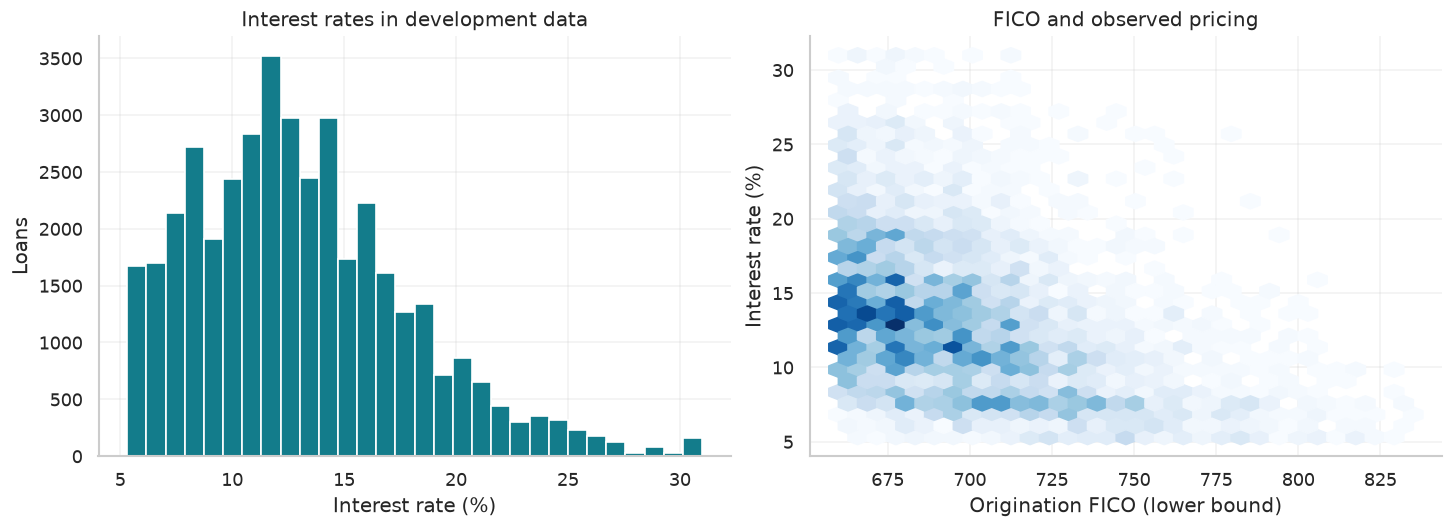

Feature 1,Feature 2,Correlation
open_acc,total_acc,0.719
fico_range_low,revol_util,-0.474
loan_amnt,revol_bal,0.320
revol_bal,revol_util,0.250
open_acc,revol_bal,0.243


In [8]:
missing=X_dev.isna().mean().mul(100).rename("Missing (%)").rename_axis("Feature").reset_index().sort_values("Missing (%)",ascending=False)
show_table(missing.head(6),2)
fig,axes=plt.subplots(1,2,figsize=(12,4.3),layout="constrained")
axes[0].hist(y_dev,bins=30,color=TEAL,edgecolor="white")
axes[0].set(title="Interest rates in development data",xlabel="Interest rate (%)",ylabel="Loans")
points=X_dev.sample(n=min(6000,len(X_dev)),random_state=SEED).index
axes[1].hexbin(X_dev.loc[points,"fico_range_low"],y_dev.loc[points],gridsize=30,mincnt=1,cmap="Blues")
axes[1].set(title="FICO and observed pricing",xlabel="Origination FICO (lower bound)",ylabel="Interest rate (%)")
finish(fig,"figure_1_pricing_eda")
corr=X_dev[NUMERIC].corr()
pairs=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack().rename("Correlation").reset_index()
pairs.columns=["Feature 1","Feature 2","Correlation"]
pairs=pairs.iloc[np.argsort(-pairs["Correlation"].abs().to_numpy())]
show_table(pairs.head(5))

### 4. What changes across the regression models

Polynomial models are still linear in their coefficients—adding an $x^2$ term just lets the line curve while keeping the actual fitting process as plain linear regression.

For two predictors, the interaction setup looks like this:

$$\hat y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_{12} x_1 x_2$$

The slope for $x_1$ becomes $\beta_1 + \beta_{12} x_2$, so its effect changes depending on $x_2$. I always keep the main effects in the model alongside any interaction term; there's rarely a good reason to drop the lower-order terms.

| Candidate | Added flexibility |
|---|---|
| **Mean baseline** | Just predicts the training fold mean |
| **Main effects** | Raw numerical features + one-hot/categorical indicators |
| **Pairwise interactions** | Products between FICO, DTI, and loan amount (no squared terms) |
| **Quadratic** | Squares and pairwise products for those three features |
| **Cubic** | Terms up to degree 3 for those same three features |

I'm using 5-fold CV RMSE to pick the final specification. Both RMSE and MAE are measured directly in interest-rate percentage points (not dollars), where lower is better, and I'm tracking $R^2$ too. Just getting a lower error on training data isn't enough to justify a more complex model. I capped the degrees at 1–3 upfront rather than constantly tweaking the degree until the visual fit looked nice.

For preprocessing, the three expansion features are imputed and scaled before generating any powers, and the resulting terms get scaled once more for numerical stability. Everything is fit strictly on the training fold within each CV split to keep data leakage out of the picture.

Evaluating Mean baseline
Evaluating Main effects
Evaluating Pairwise interactions
Evaluating Quadratic
Evaluating Cubic


Model,CV RMSE,Fold SD,CV MAE,CV R2,CV training RMSE,Encoded terms
Mean baseline,4.8358,0.0541,3.8108,-0.0001,4.8359,40
Main effects,3.7221,0.0390,2.8413,0.4075,3.7141,40
Pairwise interactions,3.7249,0.0422,2.8368,0.4065,3.7081,43
Quadratic,3.6789,0.0456,2.8039,0.4212,3.6707,46
Cubic,3.6601,0.0442,2.7875,0.4270,3.6414,56


Specification selected before test evaluation: Cubic


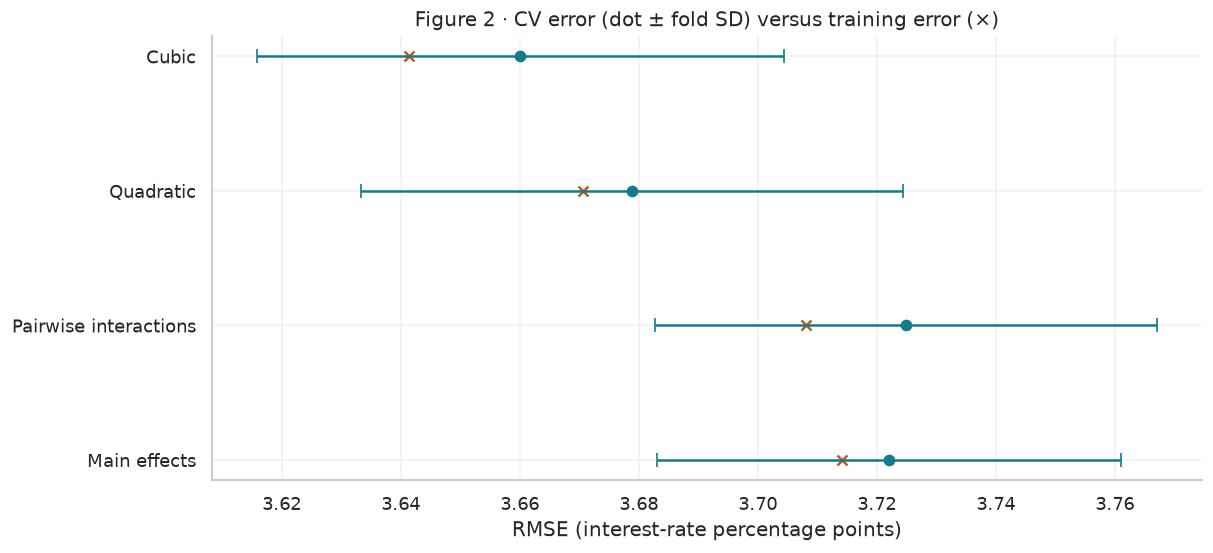

In [9]:
CORE=["fico_range_low","dti","loan_amnt"]
OTHER=[c for c in NUMERIC if c not in CORE]

def make_polynomial_model(degree=1,interactions_only=False):
    core=Pipeline([("impute",SimpleImputer(strategy="median",keep_empty_features=True)),
        ("center",StandardScaler()),
        ("terms",PolynomialFeatures(degree=degree,interaction_only=interactions_only,include_bias=False)),
        ("scale",StandardScaler())])
    other=Pipeline([("impute",SimpleImputer(strategy="median",keep_empty_features=True)),("scale",StandardScaler())])
    cats=Pipeline([("impute",SimpleImputer(strategy="constant",fill_value="Missing",keep_empty_features=True)),
        ("encode",OneHotEncoder(drop="first",handle_unknown="ignore",sparse_output=False))])
    prepare=ColumnTransformer([("core",core,CORE),("other",other,OTHER),("category",cats,CATEGORICAL)])
    return Pipeline([("prepare",prepare),("model",LinearRegression())])

specs={"Mean baseline":Pipeline([("prepare",make_preprocessor()),("model",DummyRegressor(strategy="mean"))]),
       "Main effects":make_polynomial_model(1),
       "Pairwise interactions":make_polynomial_model(2,True),
       "Quadratic":make_polynomial_model(2),"Cubic":make_polynomial_model(3)}
cv_rows=[]; fitted={}
for name,model in specs.items():
    print("Evaluating",name,flush=True)
    scores=cross_validate(model,X_dev,y_dev,cv=cv_splits,
        scoring={"rmse":"neg_root_mean_squared_error","mae":"neg_mean_absolute_error","r2":"r2"},
        return_train_score=True,n_jobs=N_JOBS,error_score="raise")
    fitted[name]=clone(model).fit(X_dev,y_dev)
    cv_rows.append({"Model":name,"CV RMSE":float(-scores["test_rmse"].mean()),
        "Fold SD":float(scores["test_rmse"].std(ddof=1)),"CV MAE":float(-scores["test_mae"].mean()),
        "CV R2":float(scores["test_r2"].mean()),"CV training RMSE":float(-scores["train_rmse"].mean()),
        "Encoded terms":len(fitted[name].named_steps["prepare"].get_feature_names_out())})
cv_results=pd.DataFrame(cv_rows)
selected_name=cv_results.loc[cv_results.Model.ne("Mean baseline")].sort_values("CV RMSE",kind="stable").iloc[0].Model
show_table(cv_results,4)
print("Specification selected before test evaluation:",selected_name)
cv_results.to_csv(OUTPUT_DIR/"cv_comparison.csv",index=False)
fig,ax=plt.subplots(figsize=(10,4.5),layout="constrained")
view=cv_results.loc[cv_results.Model.ne("Mean baseline")]
for i,row in view.reset_index(drop=True).iterrows():
    ax.errorbar(row["CV RMSE"],i,xerr=row["Fold SD"],fmt="o",color=TEAL,capsize=4)
    ax.scatter(row["CV training RMSE"],i,marker="x",color=ORANGE)
ax.set(yticks=range(len(view)),yticklabels=view.Model,xlabel="RMSE (interest-rate percentage points)",
       title="Figure 2 · CV error (dot ± fold SD) versus training error (×)")
finish(fig,"figure_2_complexity_cv")

### 5. Multicollinearity: correlation and VIF

I compare the raw quadratic numeric design matrix with the centered version, where the three expansion variables are centered prior to generating powers. Powers of a feature are often heavily correlated with the raw feature itself when the variable's values are large relative to its spread. Centering helps reduce this artificial structural correlation, though it won't fix genuine collinearity between entirely different features.

To measure multicollinearity, I calculate the Variance Inflation Factor for each numerical column:

$$\mathrm{VIF}_j = \frac{1}{1 - R_j^2}$$

Here, $R_j^2$ is obtained by regressing term $j$ on all other numeric features (including an intercept). 

- **Thresholds:** A VIF above 5 acts as a flag for further review, not an immediate trigger to drop the variable.
- **Corner cases:** Constant features are dropped before running VIF. An infinite VIF indicates exact or near-exact linear dependence across columns.

While a pairwise correlation matrix is easy to scan, it only looks at two variables at a time. VIF catches multi-way linear dependencies across several columns simultaneously, even though it requires more computation for wider design matrices. Note that these VIF calculations apply only to the numeric features, so they aren't a full diagnostic for the one-hot encoded categorical variables. Finally, because the model structure was chosen adaptively through search, I don't treat standard post-hoc $p$-values as if the model was specified *a priori*.

Design,Term,Centered powers,Raw powers
,fico_range_low,2.39,"1,064.66"
,fico_range_low^2,1.83,"1,059.59"
,fico_range_low dti,1.05,522.99
,dti,2.22,522.26
,fico_range_low loan_amnt,1.06,460.44
,loan_amnt,1.68,443.28
,loan_amnt^2,1.55,14.61
,dti loan_amnt,1.04,6.79
,open_acc,2.26,2.26
,dti^2,2.02,2.20


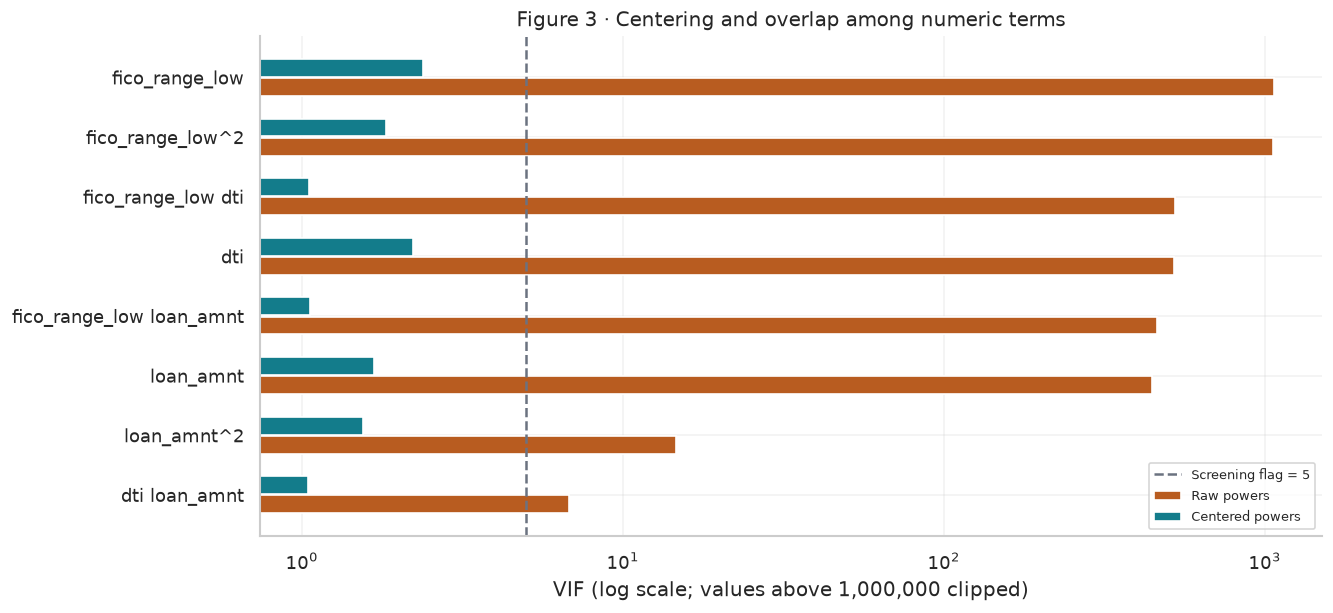

In [10]:
base=SimpleImputer(strategy="median",keep_empty_features=True).fit_transform(X_dev[NUMERIC])
base=pd.DataFrame(base,columns=NUMERIC,index=X_dev.index)
poly=PolynomialFeatures(2,include_bias=False)
raw_core=poly.fit_transform(base[CORE])
term_names=poly.get_feature_names_out(CORE).tolist()
centered_core=poly.transform(base[CORE]-base[CORE].mean())
designs={"Raw powers":np.column_stack([raw_core,base[OTHER]]),
         "Centered powers":np.column_stack([centered_core,base[OTHER]])}
vif_rows=[]
for label,array in designs.items():
    names=term_names+OTHER
    nonconstant=np.std(array,axis=0)>1e-12
    stable=StandardScaler().fit_transform(array[:,nonconstant])
    with_intercept=np.column_stack([np.ones(len(stable)),stable])
    for j,name in enumerate(np.array(names)[nonconstant],1):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore",RuntimeWarning)
            value=float(variance_inflation_factor(with_intercept,j))
        vif_rows.append({"Design":label,"Term":name,"VIF":value})
vif_table=pd.DataFrame(vif_rows)
vif_table.to_csv(OUTPUT_DIR/"numeric_vif_comparison.csv",index=False)
vif_compare=vif_table.pivot(index="Term",columns="Design",values="VIF").reset_index()
show_table(vif_compare.sort_values("Raw powers",ascending=False).head(10),2)
plot_vif=vif_compare.sort_values("Raw powers",ascending=False).head(8).iloc[::-1]
fig,ax=plt.subplots(figsize=(11,5),layout="constrained")
for offset,col,color in [(-0.16,"Raw powers",ORANGE),(0.16,"Centered powers",TEAL)]:
    values=np.clip(plot_vif[col].to_numpy(),1,1e6)
    ax.barh(np.arange(len(plot_vif))+offset,values,height=0.3,label=col,color=color)
ax.axvline(5,color=GRAY,ls="--",label="Screening flag = 5")
ax.set(yticks=range(len(plot_vif)),yticklabels=plot_vif.Term,xscale="log",xlabel="VIF (log scale; values above 1,000,000 clipped)",
       title="Figure 3 · Centering and overlap among numeric terms")
ax.legend(fontsize=8)
finish(fig,"figure_3_vif")

### 6. Visualizing an Interaction

The following illustration uses the prespecified quadratic model fit on the development data, regardless of whether it ultimately wins the CV evaluation. 

To isolate the interactions, I vary FICO score across its range while holding all other features fixed at their development medians or modes. Each line represents a different DTI level a changing slope across these lines directly reflects the fitted interaction between FICO and DTI.

Similarly, the second panel varies the loan amount across different FICO tiers. To avoid projecting into extreme extrapolation territory, feature ranges are capped between the 5th and 95th percentiles of the development set. 

A few key caveats to keep in mind:
* **Conditional, not causal:** These curves show conditional model predictions, not observed group averages or causal relationships. 
* **Distributional gaps:** Even if individual feature values fall within their 5th–95th percentile ranges, certain joint combinations may still represent sparse or unusual borrower profiles in the underlying data.
* **Sample distribution matters:** Estimating stable interactions relies on having sufficient joint coverage across combinations of features, not just a large total sample size. There is no magic sample size threshold that automatically guarantees reliable interaction estimates.

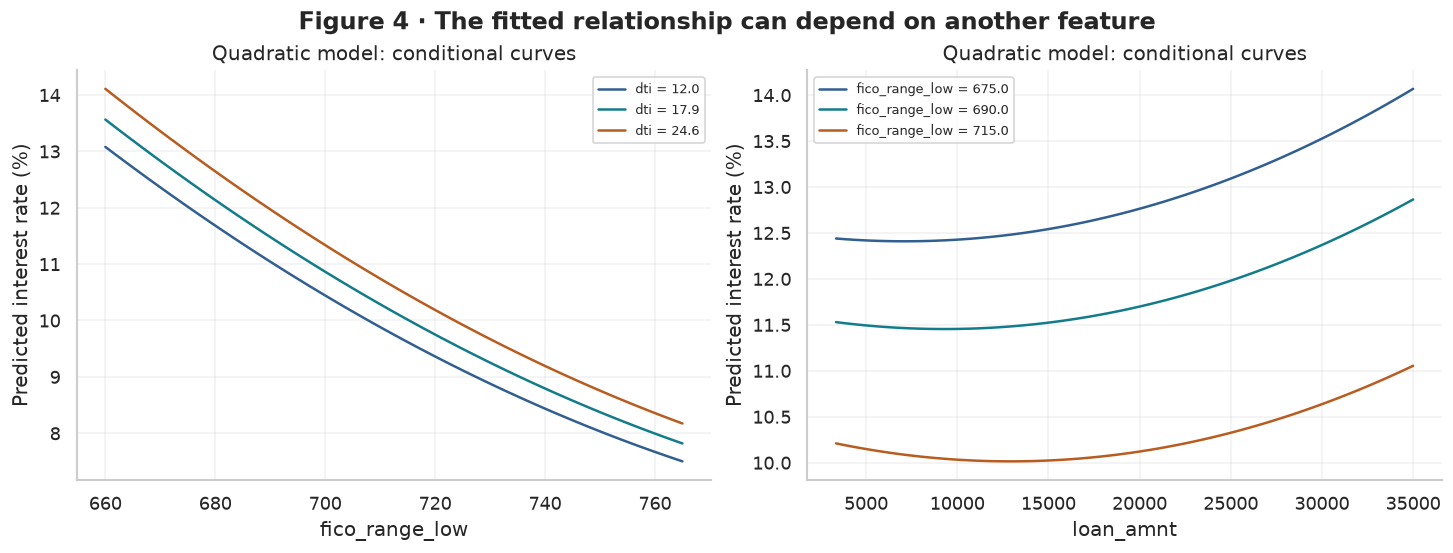

In [11]:
reference={c:float(X_dev[c].median()) for c in NUMERIC}
reference.update({c:(X_dev[c].mode().iloc[0] if len(X_dev[c].mode()) else "Missing") for c in CATEGORICAL})
illustration=fitted["Quadratic"]
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
for ax,xcol,modifier in [(axes[0],"fico_range_low","dti"),(axes[1],"loan_amnt","fico_range_low")]:
    xgrid=np.linspace(*X_dev[xcol].quantile([0.05,0.95]),100)
    for q,color in zip([0.25,0.5,0.75],[BLUE,TEAL,ORANGE]):
        level=float(X_dev[modifier].quantile(q))
        grid=pd.DataFrame([reference]*len(xgrid));grid[xcol]=xgrid;grid[modifier]=level
        ax.plot(xgrid,illustration.predict(grid),color=color,label=f"{modifier} = {level:.1f}")
    ax.set(xlabel=xcol,ylabel="Predicted interest rate (%)",title="Quadratic model: conditional curves")
    ax.legend(fontsize=8)
fig.suptitle("Figure 4 · The fitted relationship can depend on another feature",fontweight="bold")
finish(fig,"figure_4_interactions")

### 7. Held-out comparison and what I learned

The specification was chosen using development CV. I now show all prespecified models on the test split for transparency, without switching the selected model or changing the terms. The summary is generated from the results, so it will not claim an improvement before one has been measured.

Model,Training RMSE,Test RMSE,Test MAE,Test R2,CV RMSE,Fold SD,Encoded terms,CV selected
Mean baseline,4.8359,4.8988,3.8346,-0.0001,4.8358,0.0541,40,False
Main effects,3.7149,3.8022,2.8615,0.3976,3.7221,0.0390,40,False
Pairwise interactions,3.7096,3.7854,2.8551,0.4029,3.7249,0.0422,43,False
Quadratic,3.6715,3.7215,2.8063,0.4229,3.6789,0.0456,46,False
Cubic,3.6425,3.7495,2.8060,0.4142,3.6601,0.0442,56,True


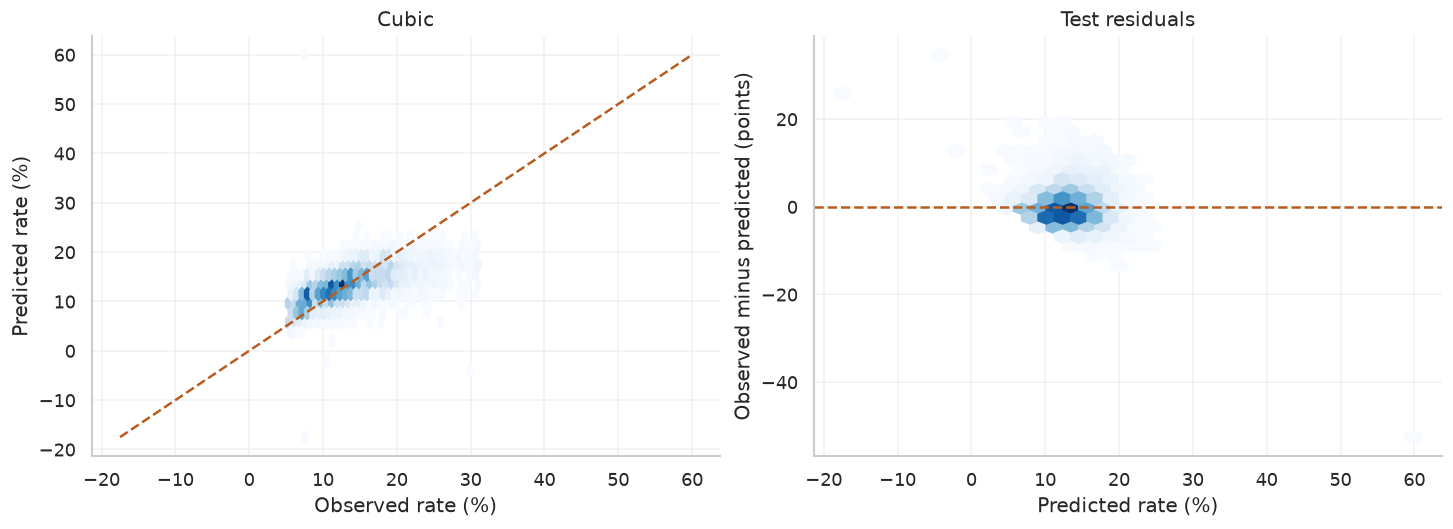

## Week 1 findings from this run

CV selected **Cubic**. Its test RMSE was **3.749 percentage points**, MAE was **2.806**, and R² was **0.414**. The main-effects model's test RMSE was **3.802**. The main-effects-minus-selected RMSE difference was **+0.0527 points**; positive means lower error for the selected specification.

CV favored additional terms. I still need to compare the size of the gain with fold variation and the added interpretation cost. I expected curved terms might help, but they do not have to improve prediction. The selected model used **56 encoded terms**, so the gain should be weighed against the extra complexity.

Training RMSE was **3.642**, compared with **3.660 in CV** and **3.749 on the test split**. These gaps show whether the extra fit carries beyond the training observations; they do not establish future performance.

The VIF comparison separates a numerical issue caused by powers from genuine overlap among predictors. The interaction curves explain what the model has fitted, but they cannot show that changing FICO or DTI would cause a different interest rate. This remains a pricing companion to my default-risk project.


In [12]:
test_results=pd.DataFrame([regression_metrics(name,model,X_dev,y_dev,X_test,y_test) for name,model in fitted.items()])
test_results=test_results.merge(cv_results[["Model","CV RMSE","Fold SD","Encoded terms"]],on="Model")
test_results["CV selected"]=test_results.Model.eq(selected_name)
show_table(test_results,4)
test_results.to_csv(OUTPUT_DIR/"test_comparison.csv",index=False)
pred=np.asarray(fitted[selected_name].predict(X_test)).ravel()
pd.DataFrame({"source_row":loans.loc[X_test.index,"source_row"].to_numpy(),"observed_rate":y_test.to_numpy(),
              "predicted_rate":pred}).to_csv(OUTPUT_DIR/"selected_test_predictions.csv",index=False)
fig,axes=plt.subplots(1,2,figsize=(12,4.3),layout="constrained")
axes[0].hexbin(y_test,pred,gridsize=35,mincnt=1,cmap="Blues")
lo=min(float(y_test.min()),float(pred.min()));hi=max(float(y_test.max()),float(pred.max()))
axes[0].plot([lo,hi],[lo,hi],color=ORANGE,ls="--")
axes[0].set(xlabel="Observed rate (%)",ylabel="Predicted rate (%)",title=selected_name)
axes[1].hexbin(pred,y_test.to_numpy()-pred,gridsize=35,mincnt=1,cmap="Blues")
axes[1].axhline(0,color=ORANGE,ls="--")
axes[1].set(xlabel="Predicted rate (%)",ylabel="Observed minus predicted (points)",title="Test residuals")
finish(fig,"figure_5_test_diagnostics")
winner=test_results.set_index("Model").loc[selected_name]
main=test_results.set_index("Model").loc["Main effects"]
improvement=float(main["Test RMSE"]-winner["Test RMSE"])
unexpected=("The main-effects model remained the CV choice. Extra flexibility did not earn its place in this search."
    if selected_name=="Main effects" else
    "CV favored additional terms. I still need to compare the size of the gain with fold variation and the added interpretation cost.")
takeaway=f"""## Week 1 findings from this run

CV selected **{selected_name}**. Its test RMSE was **{winner['Test RMSE']:.3f} percentage points**, MAE was **{winner['Test MAE']:.3f}**, and R² was **{winner['Test R2']:.3f}**. The main-effects model's test RMSE was **{main['Test RMSE']:.3f}**. The main-effects-minus-selected RMSE difference was **{improvement:+.4f} points**; positive means lower error for the selected specification.

{unexpected} I expected curved terms might help, but they do not have to improve prediction. The selected model used **{int(winner['Encoded terms'])} encoded terms**, so the gain should be weighed against the extra complexity.

Training RMSE was **{winner['Training RMSE']:.3f}**, compared with **{winner['CV RMSE']:.3f} in CV** and **{winner['Test RMSE']:.3f} on the test split**. These gaps show whether the extra fit carries beyond the training observations; they do not establish future performance.

The VIF comparison separates a numerical issue caused by powers from genuine overlap among predictors. The interaction curves explain what the model has fitted, but they cannot show that changing FICO or DTI would cause a different interest rate. This remains a pricing companion to my default-risk project.
"""
display(Markdown(takeaway))

In [13]:
run_summary={"week":1,"dataset_version":DATASET_VERSION,"sample_rows":len(loans),
    "source_rows":source_info["rows_scanned"],"seed":SEED,"python":sys.version.split()[0],
    "pandas":pd.__version__,"sklearn":sklearn.__version__,
    "sample_source_rows_sha256":hashlib.sha256(loans["source_row"].to_numpy(dtype="int64").tobytes()).hexdigest()}
run_summary.update({"target":"int_rate","selected_model":selected_name,"test_rmse":float(winner["Test RMSE"]),"test_mae":float(winner["Test MAE"]),"test_r2":float(winner["Test R2"])})
(OUTPUT_DIR/"run_summary.json").write_text(json.dumps(run_summary,indent=2))
(OUTPUT_DIR/"milestone_takeaway.md").write_text(takeaway,encoding="utf-8")
print("Saved figures, tables, settings, and the computed takeaway to",OUTPUT_DIR)

Saved figures, tables, settings, and the computed takeaway to week1_outputs


### 8. Limits, next steps, and Milestone One

OLS is sensitive to extreme observations, and a cubic curve can behave poorly outside the observed range. Centering improves numerical behavior but does not guarantee stable coefficients. Correlated terms can exchange coefficient weight. A random split also mixes loan vintages and cannot establish performance in a later economy.